# Same seed: temperature vs plan nudges (Qwen3-8B)

**Question.** Is sampling temperature really the "creativity knob" of a code LLM? Asked for a shortest-path function, Qwen3-8B almost always writes Dijkstra. Does raising the temperature make it design a *different algorithm*, or does it only *re-phrase the same one*? And does a small **plan nudge** change the algorithm under the very same token noise? The nudge is a random push on the residual stream at the task-specification tokens.

**The original experiment (`method.py`): a seed-coupled 2×2.**
- **Model:** Qwen3-8B with thinking off, run on an HF FP8 W8A8 engine on a 16 GB RTX 2000 Ada. The thinking-on arm runs in vLLM 0.11.
- **Tasks:**
  - **T2:** weighted shortest path (default Dijkstra);
  - **T1:** grid path (default BFS);
  - **T03:** k-th smallest (default full sort).
- **Token seeds:** 20 per task (5 prompt templates W1-W5 × k 0-3). **Each seed keeps one noise stream across every condition.** This is inverse-CDF common random numbers: the same uniform `u[step]` picks the next token from the CDF in every arm, so two programs of one seed differ *only* by the condition.
- **NO-PN block (temperature):** T 0.3 / 0.7 / 1.0 / 1.3, plus top-k 10 at T 0.7 and min-p 0.1 at T 2.0.
- **PN block (plan noise):**
  - 6 isotropic random directions, added to the outputs of blocks 12-23 at the task-spec positions, prefill only;
  - α = 1 or 2 "ban units";
  - T 0.7 or 1.0.
- **Thinking on:** T2 (20 seeds) and T1 (10 seeds) at the 4 temperatures, with vLLM per-request seeds (Gumbel-max coupling).
- **Labels:** every program gets a mechanism-level label (`dijkstra`, `bf_spfa`, `quickselect`, `dfs`, ...). The labeller uses hidden tests with a runtime tracer first, then AST rules, then a blind LLM judge on disagreement.

**What this notebook runs.** `method.py` is a stage orchestrator. Its sampling stages need Qwen3-8B on a compute-capability-8.9 GPU, about 2.6 GPU-hours in the original run, so they are not re-run here. Instead the notebook runs the CPU stage **`--stage analyse`**: the hash-committed analysis core (`analysis/core.py`) and the S9 analyses (`analysis/report.py`). It runs them on the real labelled programs of all 60 token seeds (`mini_demo_data.json`) and redraws the artifact's figures. With the original parameter values, which are the defaults below, it reproduces the published numbers.

**Published result (full run).** Under one fixed noise stream per seed:
- temperature changed the algorithm in **0/20 seeds** on every task, with thinking on as well;
- a plan nudge (α 1, T 1.0) changed it in **17.25/20** seeds on T2, **4.55** on T03 and **2.5** on T1;
- the pooled paired contrast is mean x_s = 0.545 [0.41, 0.67], with sign-flip p = 1e-5;
- phrasings per idea grow with T;
- verdict **PARTIAL**: H-PN fails on T03, where 4.55 < 5.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (method.py and the analysis log through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py ---
import argparse
import sys
from pathlib import Path

from loguru import logger

# --- analysis/core.py ---
import ast
import itertools
import math
from collections import Counter
from typing import Any, Callable, Iterable, Sequence

import numpy as np

# --- analysis/report.py and the src/cfg.py helpers it uses ---
import json
from collections import defaultdict
from datetime import datetime, timezone

# --- notebook additions: the `core` namespace (section 3) and inline figures (analysis/figures.py) ---
import types

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-4/experiment-21/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
if "examples" not in data:   # the copy at GITHUB_DATA_URL predates this notebook's data layout: use the local file
    print("GitHub copy has an older data layout, using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
print(f"{len(data['examples'])} token seeds, {sum(len(e['arms']) for e in data['examples'])} labelled programs")
ex = data["examples"][0]
print(ex["slot"], "->", {a: v["label"] for a, v in ex["arms"].items() if a.startswith(("NOPN", "PN_D46002_a1.0"))})

GitHub copy has an older data layout, using local mini_demo_data.json
60 token seeds, 1920 labelled programs
T2|W1|0 -> {'NOPN_T0.3': 'dijkstra', 'NOPN_T0.7': 'dijkstra', 'NOPN_T1.0': 'dijkstra', 'NOPN_T1.3': 'dijkstra', 'PN_D46002_a1.0_T0.7': 'bf_spfa', 'PN_D46002_a1.0_T1.0': 'bf_spfa'}


**The demo data.** `mini_demo_data.json` holds one record per token seed: 60 records, 20 per task. It is built from the experiment's `data/samples.jsonl` by `scripts/build_mini_demo_data.py`. Each record has:
- `slot`, `task`, `template` and `sample_id` (k), plus `input`, the exact prompt;
- `arms`: one entry per condition, every one sampled with this seed's single noise stream. Each entry has `label` (the algorithm), `passed` (hidden tests) and these extras:
  - `code` for the 4 temperature arms and the 6 directions at α 1, T 1.0;
  - the realised edit size `disp_*` for plan-noise arms;
  - `completed`, `n_think_tokens` and `first_approach` for thinking-on arms.

`metadata.reference_results` stores the values the full run published, for the comparison at the end.

The data cell checks the layout before using what it fetched. If the copy at `GITHUB_DATA_URL` comes from an earlier push of this demo, in an older layout, the cell says so and reads the local `mini_demo_data.json` instead.

## Configuration

The analysis is CPU-only. Its cost is set by how many seeds are analysed and by the resampling sizes of the permutation tests and bootstraps. Each parameter's original value, from `analysis/report.py` and `analysis/core.py`, is given in its comment. The defaults below are the original values. At these values the `analyse` stage takes about 6 s on a single CPU, and the whole notebook runs in well under a minute.

The change counts (C_T, C_PN) are exact for the seeds analysed. The p-values, CIs and bootstrap slopes match the published ones only at the original sizes, because the RNG seeds are fixed in the code.

In [5]:
# Seeds analysed: seed = (template, k) -> 5 x 4 = 20 seeds per task (all of them)
TEMPLATES_USED = ("W1", "W2", "W3", "W4", "W5")   # prompt templates                        original: ("W1", "W2", "W3", "W4", "W5")
KS_USED = (0, 1, 2, 3)          # token-seed slots per template                               original: (0, 1, 2, 3)

# Resampling sizes (all at the original values; a quick pass: 10_000 / 2_000 / 1_000 / 20 / 500 / 200 / 30)
N_DRAWS = 100_000               # sign-flip draws, pooled x_s test (H-CON)                    original: 100_000
N_DRAWS_PER_TASK = 20_000       # sign-flip draws, per-task x_s tests                         original: 20_000
SEED_BOOT_REPS = 10_000         # seed-bootstrap reps for the x_s CIs                         original: 10_000
PLACEBO_REPS = 200              # within-seed condition-shuffle placebo datasets              original: 200
N_DRAWS_PLACEBO = 5_000         # sign-flip draws per placebo dataset                         original: 5_000
PPI_BOOT_REPS = 2_000           # seed-bootstrap reps of the PPI slope (single linkage)      original: 2_000
PPI_BOOT_REPS_COMPLETE = 300    # same, complete-linkage robustness check                     original: 300

## 1. The orchestrator: `method.py`

`method.py` runs the experiment as resumable stages:

| stage | what it does | needs |
|---|---|---|
| `setup` | S0: copy and hash the inputs, check the hardware, re-check the labellers | the run volume |
| `screen` | S1 screen file + S2 power expectation | `inputs/` |
| `tests` | synthetic tests of the analysis code | CPU |
| `commit` | commit #0: the pre-registration hash chain, written before any decisive sample | CPU |
| `smoke`, `engine_check`, `grid`, `optional`, `hf_chain` | GPU unit tests, the positive control (screen rows re-run byte for byte) and the 2×2 sampling on the HF FP8 engine | Qwen3-8B on a 16 GB CC 8.9 GPU |
| `src/vllm_think.py`, `src/vllm_t1.py` | thinking-on arms in vLLM | Qwen3-8B-FP8 on a GPU |
| `label` | label worker: hidden tests, runtime tracer, AST rules, blind judge | exp8 suite / exp11 bench, OpenRouter |
| **`analyse`** | **S9: all analyses + figures (run in this notebook)** | **CPU** |
| `export`, `rederive` | `method_out.json`; independent re-derivation from `data/samples.jsonl` | CPU |

The cell below is `method.py` with two notebook changes:
- `main()` takes its arguments as a list;
- the `analyse` branch calls the `run_analysis()` defined in section 4, not `from report import run_analysis`.

The other branches import modules from the repository's `src/`, `analysis/` and `tests/` folders. They are kept as they are, but are not part of this demo.

In [6]:
ROOT = Path.cwd()   # method.py: Path(__file__).resolve().parent, with src/, analysis/ and tests/ put on sys.path


def setup_logging(stage: str) -> None:
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(ROOT / "logs" / f"{stage}.log"), rotation="30 MB", level="DEBUG")


@logger.catch(reraise=True)
def main(argv: list[str] | None = None) -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--stage", required=True,
                    choices=["setup", "screen", "tests", "commit", "smoke", "engine_check", "grid", "optional", "hf_chain",
                             "label", "analyse", "export", "rederive"])
    ap.add_argument("--tasks", default="T2,T03,T1")
    ap.add_argument("--minutes", type=float, default=None, help="wall-clock guard for GPU stages")
    ap.add_argument("--arms", default="iii,iv,ii", help="optional HF arms to run, in order")
    ap.add_argument("--follow", action="store_true", help="label worker: keep following the raw file")
    args = ap.parse_args(argv)
    setup_logging(args.stage)
    tasks = [t for t in args.tasks.split(",") if t]
    if args.stage == "setup":
        from s0_setup import run_s0
        run_s0()
    elif args.stage == "screen":
        from screen import run_screen
        run_screen()
    elif args.stage == "tests":
        from test_analysis import run_all_tests
        run_all_tests()
    elif args.stage == "commit":
        from prereg import commit0
        commit0()
    elif args.stage == "smoke":
        from grid import run_smoke
        run_smoke()
    elif args.stage == "engine_check":
        from grid import run_engine_check
        run_engine_check(minutes=args.minutes)
    elif args.stage == "grid":
        from grid import run_grid
        run_grid(tasks=tasks, minutes=args.minutes)
    elif args.stage == "optional":
        from grid import run_optional
        run_optional(arms=[a for a in args.arms.split(",") if a], minutes=args.minutes)
    elif args.stage == "hf_chain":
        from grid import run_hf_chain
        run_hf_chain(tasks=tasks, arms=[a for a in args.arms.split(",") if a], minutes=args.minutes)
    elif args.stage == "label":
        from label4 import run_labels
        run_labels(follow=args.follow, minutes=args.minutes)
    elif args.stage == "analyse":
        run_analysis()   # method.py: from report import run_analysis (defined in section 4 of this notebook)
    elif args.stage == "export":
        from export import run_export
        run_export()
    elif args.stage == "rederive":
        import runpy
        runpy.run_path(str(ROOT / "audit" / "rederive.py"), run_name="__main__")

## 2. Experiment constants (`src/cfg4.py`)

The condition grid and the condition-string helpers. Every program row carries an `arm` string such as `NOPN_T0.7`, `TOPK10_T0.7`, `MINP_T2.0`, `PN_D46002_a1.0_T1.0` or `THINK_T1.3`. `PN_D<seed>` names one of the 6 random unit directions, built from `PCG64(seed).standard_normal(4096)`. Only the constants the analysis reads are copied here; the sampler, KV-cache and vLLM settings stay in the repository.

In [7]:
DEFAULT4 = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort"}
TEMPS = (0.3, 0.7, 1.0, 1.3)
TOPK_T, TOPK_K = 0.7, 10
PN_TEMPS = (0.7, 1.0)
PN_ALPHAS = (1.0, 2.0)
PN_SEEDS = (46001, 46002, 46003, 46004, 46005, 46006)   # D1-D6 (collision check in S0)
SEED_K = (0, 1, 2, 3)
MINP_T, MINP_P = 2.0, 0.1


def fmt_t(t: float) -> str:
    return f"{float(t):.1f}"


def cond_nopn(t: float) -> str:
    return f"NOPN_T{fmt_t(t)}"


def cond_pn(seed: int, alpha: float, t: float) -> str:
    return f"PN_D{seed}_a{float(alpha):.1f}_T{fmt_t(t)}"

## 3. The pre-registered analysis core (`analysis/core.py`)

This file was hash-committed in commit #0, before any decisive sample was drawn. It is copied verbatim below, split into four cells. Its module docstring quotes the committed definitions. In plain words:
- **Valid labels.** Only valid labels count. `invalid` (no code, syntax error, crash before the first traced op) and `unresolved` programs are excluded.
- **`changed(labels)`** is 1 when a seed's programs implement two or more different algorithms, and 0 when they all implement the same one.
- **C_T** is the number of seeds whose algorithm changes across the 4 temperatures. Thanks to the shared noise stream, a change can only come from the temperature.
- **C_PN** is the number of seeds whose algorithm changes across {NO-PN} ∪ {3 plan-noise directions}, averaged over all C(6,3) = 20 direction subsets.
- **x_s** is the paired seed-level contrast changed_PN − changed_T, tested with a one-sided sign-flip permutation test.

### 3a. Labels, indexing and change counts

In [8]:
"""C1-seed analysis core (hash-committed in commit #0 before any decisive sample).

Definitions (verbatim from predictions/prereg_c1seed.json):
- A SEED is a slot (task, template w, k); 20 per task (W1-W5 x k 0-3).
- Label modes: 'primary' = catalogue label or 'other' of VALID programs ('invalid' = no code / syntax error / crash
  before the first traced op, and 'unresolved' (incl. exp17's 'disputed') are excluded); 'correct_only' = primary and
  passed the hidden tests; 'invalid_as_label' = 'invalid' counts as one more label value.
- changed(labels) = 1 if the valid labels contain >= 2 distinct values, 0 if they are all equal, None if fewer than
  2 valid labels (seed not countable for that set).
- changed_T(s) over {NOPN T0.3, T0.7, T1.0, T1.3}; changed_PN(s; S, alpha, T) over {NOPN at T} + {PN(d, alpha, T): d in S}.
- C_T = sum over countable seeds of changed_T; C_PN = mean over all C(6,3) = 20 subsets S of sum_s changed_PN(s; S)
  (uncountable (seed, S) pairs contribute 0 and are reported).
- x_s = mean over countable subsets of changed_PN(s; S, alpha 1, T 1.0) - changed_T(s), for seeds where both are
  defined; one-sided sign-flip permutation p (100,000 draws) for mean x_s > 0, pooled over T2 and T03 seeds.
- Phrasing: identifier-normalised AST 4-gram shingles, Jaccard, connected components at theta (complete linkage as
  robustness) within each (condition, idea); PPI = clusters / ideas present; slope of log PPI on T per task by seed
  bootstrap; pooled slope = mean of the task slopes.
"""

EXCLUDED = {"invalid", "unresolved", "disputed", None, ""}
THETAS = (0.7, 0.8, 0.9)
SUBSET_SIZE = 3


# ------------------------------------------------------------------------------------------------ labels
def norm_label(lab: str | None) -> str | None:
    if lab in ("disputed", "unresolved", "unknown", "inconsistent"):
        return "unresolved"
    return lab


def label_value(row: dict[str, Any] | None, mode: str = "primary") -> str | None:
    """Label used for change counting under a sensitivity mode; None = excluded."""
    if row is None:
        return None
    lab = norm_label(row.get("label"))
    if mode == "primary":
        return None if lab in EXCLUDED else lab
    if mode == "correct_only":
        return lab if (lab not in EXCLUDED and bool(row.get("passed"))) else None
    if mode == "invalid_as_label":
        return None if lab in ("unresolved", None, "") else lab
    if mode == "first_approach":
        return row.get("first_approach")
    raise ValueError(mode)


def changed(labels: Iterable[str | None], min_valid: int = 2) -> int | None:
    v = [l for l in labels if l is not None]
    if len(v) < min_valid:
        return None
    return int(len(set(v)) >= 2)


# ------------------------------------------------------------------------------------------------ indexing
def index_rows(rows: Iterable[dict[str, Any]]) -> dict[tuple[str, str, str], dict[str, Any]]:
    """{(task, seed_id, arm): row}; seed_id = 'W1|0'. Later duplicates are ignored (first row wins)."""
    out: dict[tuple[str, str, str], dict[str, Any]] = {}
    for r in rows:
        key = (r["task"], f"{r['template']}|{int(r['sample_id'])}", r["arm"])
        out.setdefault(key, r)
    return out


def seeds_of(templates: Sequence[str] = ("W1", "W2", "W3", "W4", "W5"), ks: Sequence[int] = (0, 1, 2, 3)) -> list[str]:
    return [f"{w}|{k}" for w in templates for k in ks]


# ------------------------------------------------------------------------------------------------ change counts
def changed_over(idx: dict, task: str, seed: str, arms: Sequence[str], mode: str = "primary") -> int | None:
    return changed([label_value(idx.get((task, seed, a)), mode) for a in arms])


def count_changed(idx: dict, task: str, seeds: Sequence[str], arms: Sequence[str],
                  mode: str = "primary") -> dict[str, Any]:
    per = {s: changed_over(idx, task, s, arms, mode) for s in seeds}
    vals = [v for v in per.values() if v is not None]
    return {"C": int(sum(vals)), "n_countable": len(vals), "n_seeds": len(seeds), "per_seed": per}


def subsets(items: Sequence[Any], k: int = SUBSET_SIZE) -> list[tuple[Any, ...]]:
    return list(itertools.combinations(list(items), k))


def c_pn(idx: dict, task: str, seeds: Sequence[str], nopn_arm: str, pn_arms: Sequence[str],
         mode: str = "primary", k: int = SUBSET_SIZE) -> dict[str, Any]:
    """Subset-averaged changed-seed count over all C(len(pn_arms), k) subsets."""
    subs = subsets(pn_arms, k)
    sums, uncountable = [], 0
    per_seed_mean: dict[str, float | None] = {}
    per_seed_vals: dict[str, list[int]] = {s: [] for s in seeds}
    for S in subs:
        tot = 0
        for s in seeds:
            v = changed_over(idx, task, s, [nopn_arm, *S], mode)
            if v is None:
                uncountable += 1
                continue
            tot += v
            per_seed_vals[s].append(v)
        sums.append(tot)
    for s in seeds:
        per_seed_mean[s] = float(np.mean(per_seed_vals[s])) if per_seed_vals[s] else None
    arr = np.array(sums, dtype=float)
    return {"C_PN": float(arr.mean()) if len(arr) else float("nan"), "min": float(arr.min()) if len(arr) else None,
            "median": float(np.median(arr)) if len(arr) else None, "max": float(arr.max()) if len(arr) else None,
            "n_subsets": len(subs), "uncountable_seed_subsets": uncountable, "subset_sums": sums,
            "per_seed_mean": per_seed_mean}


def x_contrast(changed_t: dict[str, int | None], pn_mean: dict[str, float | None]) -> dict[str, float]:
    """x_s = subset-mean changed_PN(s) - changed_T(s) over seeds where both are defined."""
    return {s: float(pn_mean[s]) - float(changed_t[s]) for s in changed_t
            if changed_t.get(s) is not None and pn_mean.get(s) is not None}

### 3b. Statistics: sign-flip test, seed bootstrap, Clopper-Pearson bound

- `sign_flip_p` is the committed H-CON test. Under the null, each seed's x_s is symmetric around 0, so its sign is flipped at random; p = (1 + #{flipped mean ≥ observed}) / (1 + draws).
- `seed_bootstrap_ci` resamples seeds.
- `clopper_pearson` gives the exact binomial interval. A count of 0/20 changed seeds still allows a per-seed change rate of up to 0.168.

In [9]:
def sign_flip_p(x: Sequence[float], n_draws: int = 100_000, seed: int = 20261021) -> dict[str, Any]:
    """One-sided sign-flip permutation test of mean(x) > 0. p = (1 + #{perm mean >= obs}) / (1 + n_draws)."""
    xa = np.asarray(list(x), dtype=float)
    n = len(xa)
    if n == 0:
        return {"n": 0, "mean": float("nan"), "p": float("nan")}
    obs = float(xa.mean())
    if np.allclose(xa, 0):
        return {"n": n, "mean": obs, "p": 1.0, "n_draws": 0, "note": "all x_s = 0"}
    rng = np.random.default_rng(seed)
    ge = 0
    chunk = 10_000
    done = 0
    while done < n_draws:
        m = min(chunk, n_draws - done)
        signs = rng.integers(0, 2, size=(m, n), dtype=np.int8) * 2 - 1
        means = (signs * xa[None, :]).mean(axis=1)
        ge += int((means >= obs - 1e-12).sum())
        done += m
    return {"n": n, "mean": obs, "p": (1 + ge) / (1 + n_draws), "n_draws": n_draws, "n_nonzero": int((xa != 0).sum())}


def seed_bootstrap_ci(x: Sequence[float], reps: int = 10_000, seed: int = 7, level: float = 0.95) -> tuple[float, float]:
    xa = np.asarray(list(x), dtype=float)
    if len(xa) == 0:
        return (float("nan"), float("nan"))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(xa), size=(reps, len(xa)))
    m = xa[idx].mean(axis=1)
    a = (1 - level) / 2
    return (float(np.quantile(m, a)), float(np.quantile(m, 1 - a)))


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    from scipy.stats import beta

    if n == 0:
        return (float("nan"), float("nan"))
    a = (1 - level) / 2
    lo = 0.0 if k == 0 else float(beta.ppf(a, k, n - k + 1))
    hi = 1.0 if k == n else float(beta.ppf(1 - a, k + 1, n - k))
    return (lo, hi)

### 3c. Phrasings: AST shingles, Jaccard clusters, phrasings per idea (PPI)

This is how the code tells an *idea* from a *phrasing*:
1. Each program is linearised into its AST node types. Identifiers are renamed by order of first appearance, constants are reduced to their type, and docstrings and comments are dropped.
2. The token sequence is cut into 4-gram shingles.
3. Two programs of the same idea count as the same **phrasing** when their shingle Jaccard is ≥ θ. Clusters are connected components (single linkage), with complete linkage as a robustness check.
4. **PPI** = phrasing clusters / ideas present in a cell. The slope of log PPI on T is bootstrapped over seeds.

In [10]:
# ------------------------------------------------------------------------------------------------ shingles
class _Norm(ast.NodeVisitor):
    """Pre-order linearisation: node type names, operator classes, renamed identifiers (first appearance), constants
    as their type only. Docstrings are dropped (comments never reach the AST)."""

    def __init__(self) -> None:
        self.toks: list[str] = []
        self.names: dict[str, str] = {}

    def _id(self, name: str) -> str:
        if name not in self.names:
            self.names[name] = f"v{len(self.names)}"
        return self.names[name]

    def generic_visit(self, node: ast.AST) -> None:
        self.toks.append(type(node).__name__)
        for field, value in ast.iter_fields(node):
            if isinstance(value, list):
                body = value
                if field == "body" and body and isinstance(body[0], ast.Expr) and isinstance(
                        getattr(body[0], "value", None), ast.Constant) and isinstance(body[0].value.value, str):
                    body = body[1:]           # drop docstring
                for item in body:
                    if isinstance(item, ast.AST):
                        self.visit(item)
            elif isinstance(value, ast.AST):
                self.visit(value)
            elif field in ("id", "arg", "name", "asname") and isinstance(value, str):
                self.toks.append(self._id(value))
            elif field == "attr" and isinstance(value, str):
                self.toks.append("." + value)
            elif field == "module" and isinstance(value, str):
                self.toks.append("mod:" + value)

    def visit_Constant(self, node: ast.Constant) -> None:
        self.toks.append("Const:" + type(node.value).__name__)


def ast_tokens(code: str) -> list[str] | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, MemoryError, RecursionError):
        return None
    v = _Norm()
    try:
        v.visit(tree)
    except RecursionError:
        return None
    return v.toks


def shingles(code: str | None, n: int = 4) -> frozenset | None:
    if not code:
        return None
    toks = ast_tokens(code)
    if toks is None:
        return None
    if len(toks) < n:
        return frozenset([tuple(toks)])
    return frozenset(tuple(toks[i:i + n]) for i in range(len(toks) - n + 1))


def jaccard(a: frozenset | None, b: frozenset | None) -> float:
    if a is None or b is None:
        return float("nan")
    if not a and not b:
        return 1.0
    return len(a & b) / max(len(a | b), 1)


def jaccard_matrix(sh: Sequence[frozenset]) -> np.ndarray:
    n = len(sh)
    m = np.eye(n)
    for i in range(n):
        for j in range(i + 1, n):
            m[i, j] = m[j, i] = jaccard(sh[i], sh[j])
    return m


def n_components(J: np.ndarray, theta: float) -> int:
    """Connected components of the graph with an edge where Jaccard >= theta (single linkage)."""
    n = J.shape[0]
    if n == 0:
        return 0
    parent = list(range(n))

    def find(a: int) -> int:
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i in range(n):
        for j in range(i + 1, n):
            if J[i, j] >= theta - 1e-12:
                ri, rj = find(i), find(j)
                if ri != rj:
                    parent[ri] = rj
    return len({find(i) for i in range(n)})


def n_complete(J: np.ndarray, theta: float) -> int:
    """Complete-linkage clusters cut at distance 1 - theta (robustness)."""
    from scipy.cluster.hierarchy import fcluster, linkage
    from scipy.spatial.distance import squareform

    n = J.shape[0]
    if n <= 1:
        return n
    D = np.clip(1.0 - J, 0.0, 1.0)
    np.fill_diagonal(D, 0.0)
    Z = linkage(squareform(D, checks=False), method="complete")
    return int(len(set(fcluster(Z, t=1.0 - theta + 1e-12, criterion="distance"))))


def ppi(labels: Sequence[str], J: np.ndarray, theta: float, linkage_kind: str = "single") -> dict[str, Any]:
    """Phrasings per idea of one cell: programs grouped by idea label; clusters within each idea; PPI = clusters /
    ideas present. labels[i] is the idea of program i (J indexes the same programs)."""
    ideas = sorted(set(labels))
    if not ideas:
        return {"ppi": float("nan"), "clusters": 0, "ideas": 0, "by_idea": {}}
    by = {}
    tot = 0
    for idea in ideas:
        ii = [i for i, l in enumerate(labels) if l == idea]
        sub = J[np.ix_(ii, ii)]
        c = n_components(sub, theta) if linkage_kind == "single" else n_complete(sub, theta)
        by[idea] = {"n": len(ii), "clusters": c}
        tot += c
    return {"ppi": tot / len(ideas), "clusters": tot, "ideas": len(ideas), "by_idea": by}


def ols_slope(x: Sequence[float], y: Sequence[float]) -> float:
    xa, ya = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(ya)
    xa, ya = xa[ok], ya[ok]
    if len(xa) < 2 or np.ptp(xa) == 0:
        return float("nan")
    xm = xa - xa.mean()
    return float((xm * (ya - ya.mean())).sum() / (xm ** 2).sum())


def ppi_slope_bootstrap(cells: dict[float, dict[str, Any]], theta: float, reps: int = 2000, seed: int = 11,
                        linkage_kind: str = "single") -> dict[str, Any]:
    """cells[T] = {'seeds': [seed ids], 'labels': [idea per seed program], 'sh': [shingles]} for the NO-PN cells of one
    task (programs aligned by seed; a seed with no valid program at T is absent from that cell). The bootstrap
    resamples SEEDS (each seed's coupled programs move together)."""
    Ts = sorted(cells)
    allseeds = sorted({s for T in Ts for s in cells[T]["seeds"]})
    pos = {T: {s: i for i, s in enumerate(cells[T]["seeds"])} for T in Ts}
    Js = {T: jaccard_matrix(cells[T]["sh"]) for T in Ts}

    def stat(seed_list: list[str]) -> tuple[float, dict[float, float]]:
        vals = {}
        for T in Ts:
            ii = [pos[T][s] for s in seed_list if s in pos[T]]
            if not ii:
                vals[T] = float("nan")
                continue
            labs = [cells[T]["labels"][i] for i in ii]
            J = Js[T][np.ix_(ii, ii)]
            vals[T] = ppi(labs, J, theta, linkage_kind)["ppi"]
        return ols_slope(Ts, [math.log(v) if v and v > 0 else float("nan") for v in vals.values()]), vals
    obs, obs_vals = stat(allseeds)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(reps):
        samp = [allseeds[i] for i in rng.integers(0, len(allseeds), size=len(allseeds))]
        boots.append(stat(samp)[0])
    b = np.array([v for v in boots if np.isfinite(v)])
    return {"slope": obs, "ppi_by_T": {str(k): v for k, v in obs_vals.items()}, "boot": b,
            "ci95": (float(np.quantile(b, 0.025)), float(np.quantile(b, 0.975))) if len(b) else (float("nan"),) * 2}

### 3d. Diversity, divergences and the committed verdict rules

- `hill1` is the effective number of ideas: the exponential of the Shannon entropy of the labels.
- `js_bits` and `template_resampling_null` serve the engine check and the FP8 cross-check, which are not run here.
- `decide` applies the outcome rules exactly as committed:
  - **H-T** (temperature is inert): C_T ≤ 1 in every cell, thinking off and on.
  - **H-PN** (plan noise moves ideas): C_PN(α 1, T 1.0) ≥ 5 on T2 *and* on T03.
  - **H-PHR** (temperature grows phrasings): the pooled PPI slope is > 0, with CI above 0, at every θ.
  - **H-CON** (the paired contrast): mean x_s > 0 with p < 0.05.

`report.py` and `figures.py` import this file as a module and call `core.<name>`. The last lines of the cell collect the core definitions under that name.

In [11]:
# ------------------------------------------------------------------------------------------------ diversity
def hill1(labels: Sequence[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    p = np.array(list(c.values()), float) / n
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill1(per_seed_options: dict[str, list[str | None]], draws: int = 1000, seed: int = 5) -> dict[str, Any]:
    """per_seed_options[s] = labels (None = not counted, e.g. not correct) of the seed's programs in a PN cell (one per
    direction). Each draw takes one program per seed (depth = number of seeds) and computes Hill-1 over the counted
    labels."""
    rng = np.random.default_rng(seed)
    seeds = sorted(per_seed_options)
    vals, depths = [], []
    for _ in range(draws):
        labs = []
        for s in seeds:
            opts = per_seed_options[s]
            if not opts:
                continue
            l = opts[int(rng.integers(0, len(opts)))]
            if l is not None:
                labs.append(l)
        if labs:
            vals.append(hill1(labs))
            depths.append(len(labs))
    return {"hill1_mean": float(np.mean(vals)) if vals else float("nan"),
            "hill1_q05": float(np.quantile(vals, 0.05)) if vals else float("nan"),
            "hill1_q95": float(np.quantile(vals, 0.95)) if vals else float("nan"),
            "mean_counted_depth": float(np.mean(depths)) if depths else 0.0}


def js_bits(c1: Counter | dict, c2: Counter | dict) -> float:
    keys = sorted(set(c1) | set(c2))
    p = np.array([c1.get(k, 0) for k in keys], float)
    q = np.array([c2.get(k, 0) for k in keys], float)
    if p.sum() == 0 or q.sum() == 0:
        return float("nan")
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        ok = a > 0
        return float((a[ok] * np.log2(a[ok] / b[ok])).sum())
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def template_resampling_null(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], key: Callable[[dict], Any],
                             reps: int = 2000, seed: int = 3) -> dict[str, Any]:
    """JS between two compositions vs a null that pools both arms and resamples templates (with replacement, within the
    pooled arm) to form two pseudo-arms of the original template counts."""
    obs = js_bits(Counter(key(r) for r in rows_a if key(r) is not None),
                  Counter(key(r) for r in rows_b if key(r) is not None))
    pool = rows_a + rows_b
    by_t: dict[str, list[dict[str, Any]]] = {}
    for r in pool:
        by_t.setdefault(r["template"], []).append(r)
    temps = sorted(by_t)
    rng = np.random.default_rng(seed)
    null = []
    na = Counter(r["template"] for r in rows_a)
    nb = Counter(r["template"] for r in rows_b)
    for _ in range(reps):
        def pseudo(counts: Counter) -> Counter:
            c: Counter = Counter()
            for w, n in counts.items():
                src = by_t[temps[int(rng.integers(0, len(temps)))]]
                for i in rng.integers(0, len(src), size=n):
                    v = key(src[int(i)])
                    if v is not None:
                        c[v] += 1
            return c
        null.append(js_bits(pseudo(na), pseudo(nb)))
    nb_ = np.array([v for v in null if np.isfinite(v)])
    return {"js_bits": obs, "null_p95": float(np.quantile(nb_, 0.95)) if len(nb_) else float("nan"),
            "p": float((1 + (nb_ >= obs - 1e-12).sum()) / (1 + len(nb_))) if len(nb_) else float("nan")}


# ------------------------------------------------------------------------------------------------ verdict
def decide(res: dict[str, Any]) -> dict[str, Any]:
    """Apply the committed outcome rules. res keys: C_T[cell] (ints), C_PN_a1_T1[task] (floats), phr[theta] = {slope,
    ci95}, hcon = {mean, p}."""
    ht_cells = res["C_T"]
    h_t = all(v is not None and v <= 1 for v in ht_cells.values())
    h_pn = all(res["C_PN_a1_T1"].get(t, 0) >= 5 for t in ("T2", "T03"))
    h_phr = all(np.isfinite(v["slope"]) and v["slope"] > 0 and v["ci95"][0] > 0 for v in res["phr"].values())
    h_con = res["hcon"]["p"] < 0.05 and res["hcon"]["mean"] > 0
    disconf = (res["hcon"]["mean"] <= 0) or all(
        (res["C_T_off"].get(t, 0) >= res["C_PN_a1_T1"].get(t, 0)) for t in ("T2", "T03"))
    if h_t and h_pn and h_phr and h_con:
        verdict = "CONFIRMED"
    elif disconf:
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    failed = [n for n, ok in (("H-T", h_t), ("H-PN", h_pn), ("H-PHR", h_phr), ("H-CON", h_con)) if not ok]
    note = ""
    if verdict == "PARTIAL" and h_t and all(1 <= res["C_PN_a1_T1"].get(t, 0) <= 4 for t in ("T2", "T03")):
        note = "temperature inert but PN weaker than predicted"
    return {"verdict": verdict, "H-T": h_t, "H-PN": h_pn, "H-PHR": h_phr, "H-CON": h_con, "failed_parts": failed,
            "note": note}


# notebook: report.py and figures.py import analysis/core.py as `core`; collect the definitions of the four core cells
# under that name (re-run this cell after editing a core function)
core = types.SimpleNamespace(**{n: globals()[n] for n in (
    "EXCLUDED", "THETAS", "SUBSET_SIZE", "norm_label", "label_value", "changed", "index_rows", "seeds_of",
    "changed_over", "count_changed", "subsets", "c_pn", "x_contrast", "sign_flip_p", "seed_bootstrap_ci",
    "clopper_pearson", "ast_tokens", "shingles", "jaccard", "jaccard_matrix", "n_components", "n_complete", "ppi",
    "ols_slope", "ppi_slope_bootstrap", "hill1", "rarefied_hill1", "js_bits", "template_resampling_null", "decide")})

## 4. The S9 analyses (`analysis/report.py`)

### 4a. Loading the labelled programs

In the repository, `load_rows()` joins `data/samples_raw.jsonl` (generations) with `data/labels.jsonl` (label, pass and extracted code). Here the same fields come from the loaded `data`; that is the only change in this cell. `core.index_rows` then keys every program by (task, seed, arm), so one seed's programs can be lined up across conditions. `SEEDS` comes from the config cell; with the original values it equals `core.seeds_of()`, all 20 seeds per task.

The cell also copies the small `src/cfg.py` helpers that `report.py` imports: `utc_now`, `wilson_ci` and `write_json`. Results go to `results/`, as in the repository.

In [12]:
# ------------------------------------------------------------------------------------------------ src/cfg.py helpers
def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"

# ------------------------------------------------------------------------------------------------ report.py
TASKS = ("T2", "T03", "T1")
TEMP_ARMS = [cond_nopn(t) for t in TEMPS]
TOPK_ARM = f"TOPK{TOPK_K}_T{fmt_t(TOPK_T)}"
MINP_ARM = f"MINP_T{fmt_t(MINP_T)}"
THINK_ARMS = [f"THINK_T{fmt_t(t)}" for t in TEMPS]
SEEDS = core.seeds_of(TEMPLATES_USED, KS_USED)   # report.py: core.seeds_of() = W1-W5 x k 0-3
COUPLING = {"off": "inverse-CDF CRN (PCG64 uniforms, vocabulary order)",
            "on": "vLLM exponential race = Gumbel-max (per-request seed)",
            "gumbel": "HF exponential race = Gumbel-max (per-row CUDA generator)"}


# ------------------------------------------------------------------------------------------------ data
def load_rows() -> list[dict[str, Any]]:
    # notebook: generations and labels come from `data` (one record per token seed, one entry per arm) instead of
    # data/samples_raw.jsonl joined with data/labels.jsonl; only the seeds chosen in the config cell are loaded
    out = []
    for ex in data["examples"]:
        if f"{ex['template']}|{ex['sample_id']}" not in SEEDS:
            continue
        for arm, l in ex["arms"].items():
            r = {"task": ex["task"], "template": ex["template"], "arm": arm, "sample_id": ex["sample_id"],
                 "slot": ex["slot"], **{k: v for k, v in l.items() if k not in ("label", "passed", "code")}}
            key = f"{r['task']}|{r['template']}|{r['arm']}|{r['sample_id']}"
            out.append({**r, "key": key, "label": l["label"] if l else None, "passed": bool(l and l["passed"]),
                        "labelled": l is not None, "code": l.get("code") if l else None})
    return out


def rows_for(rows: list[dict[str, Any]], task: str, arm: str) -> list[dict[str, Any]]:
    return [r for r in rows if r["task"] == task and r["arm"] == arm]


def comp(rows: list[dict[str, Any]], correct: bool = False) -> dict[str, int]:
    c = Counter(core.label_value(r, "correct_only" if correct else "primary") for r in rows)
    c.pop(None, None)
    return dict(c.most_common())


def cp_rate(k: int, n: int) -> dict[str, Any]:
    lo, hi = core.clopper_pearson(k, n)
    return {"k": k, "n": n, "rate": k / n if n else None, "cp95": [lo, hi]}


print(f"{len(SEEDS)} seeds per task: {SEEDS}")

20 seeds per task: ['W1|0', 'W1|1', 'W1|2', 'W1|3', 'W2|0', 'W2|1', 'W2|2', 'W2|3', 'W3|0', 'W3|1', 'W3|2', 'W3|3', 'W4|0', 'W4|1', 'W4|2', 'W4|3', 'W5|0', 'W5|1', 'W5|2', 'W5|3']


### 4b. A1: the temperature change count C_T · A2: the plan-noise change count C_PN

- **`a1_ct`** counts the seeds whose algorithm changes across the 4 temperatures. It reports three label modes (primary, correct-only, invalid-as-label) and the exact Clopper-Pearson bound.
- **`pairwise_t`** repeats the count for every pair of temperatures.
- **`a2_cpn`** computes C_PN for each (α, T) cell: the mean over the 20 direction subsets, the subset range, and a correct-only version.
- **`per_direction`** describes each direction on its own:
  - the share of off-default programs and the pass rate;
  - where the nudged programs land (for example `bf_spfa` instead of `dijkstra`);
  - the realised edit size `disp_*`;
  - the descriptive "escape" rule: excess off-default share ≥ 0.20 and pass ratio ≥ 0.85.

In [13]:
# ------------------------------------------------------------------------------------------------ A1-A3
def a1_ct(idx: dict, task: str, arms: list[str], seeds: list[str] = SEEDS) -> dict[str, Any]:
    out = {}
    for mode in ("primary", "correct_only", "invalid_as_label"):
        c = core.count_changed(idx, task, seeds, arms, mode)
        out[mode] = {"C_T": c["C"], "n_countable": c["n_countable"], "cp95_rate": cp_rate(c["C"], c["n_countable"]),
                     "changed_seeds": sorted(s for s, v in c["per_seed"].items() if v)}
    return out


def pairwise_t(idx: dict, task: str, arms: list[str]) -> dict[str, Any]:
    out = {}
    for a, b in __import__("itertools").combinations(arms, 2):
        c = core.count_changed(idx, task, SEEDS, [a, b])
        out[f"{a}|{b}"] = {"changed": c["C"], "n": c["n_countable"]}
    return out


def a2_cpn(idx: dict, task: str, prefix: str = "") -> dict[str, Any]:
    out = {}
    for a in PN_ALPHAS:
        for t in PN_TEMPS:
            arms = [prefix + cond_pn(d, a, t) for d in PN_SEEDS]
            if not any((task, s, arms[0]) in idx for s in SEEDS):
                continue
            r = core.c_pn(idx, task, SEEDS, prefix + cond_nopn(t), arms)
            rc = core.c_pn(idx, task, SEEDS, prefix + cond_nopn(t), arms, mode="correct_only")
            out[f"a{a:.1f}_T{fmt_t(t)}"] = {"C_PN": r["C_PN"], "min": r["min"], "median": r["median"], "max": r["max"],
                                            "subset_sums": r["subset_sums"], "uncountable": r["uncountable_seed_subsets"],
                                            "C_PN_correct_only": rc["C_PN"], "per_seed_mean": r["per_seed_mean"]}
    return out


def per_direction(rows: list[dict[str, Any]], task: str, prefix: str = "") -> dict[str, Any]:
    out = {}
    de = DEFAULT4[task]
    for t in PN_TEMPS:
        base = rows_for(rows, task, prefix + cond_nopn(t))
        bv = [core.label_value(r) for r in base]
        bv = [x for x in bv if x]
        b_off = sum(x != de for x in bv) / max(len(bv), 1)
        b_pass = sum(r["passed"] for r in base) / max(len(base), 1)
        for a in PN_ALPHAS:
            for d in PN_SEEDS:
                rr = rows_for(rows, task, prefix + cond_pn(d, a, t))
                if not rr:
                    continue
                v = [core.label_value(r) for r in rr]
                v = [x for x in v if x]
                off = sum(x != de for x in v) / max(len(v), 1)
                pr = sum(r["passed"] for r in rr) / max(len(rr), 1)
                out[f"D{d}_a{a:.1f}_T{fmt_t(t)}"] = {
                    "N": len(rr), "n_valid": len(v), "share_off": off, "nopn_share_off": b_off,
                    "excess": off - b_off, "pass_rate": pr, "pass_ratio": pr / max(b_pass, 1e-9),
                    "escape_descriptive": (off - b_off >= 0.20 and pr / max(b_pass, 1e-9) >= 0.85),
                    "landing": dict(Counter(x for x in v if x != de).most_common()),
                    "mean_disp_S_b23": float(np.mean([r.get("disp_S_mean_b23") or 0 for r in rr])),
                    "mean_disp_S_b35": float(np.mean([r.get("disp_S_mean_b35") or 0 for r in rr])),
                    "mean_disp_R_b35": float(np.mean([r.get("disp_R_b35") or 0 for r in rr]))}
    return out

### 4c. A3: the paired seed contrast x_s (the committed H-CON test)

For every seed, x_s = (mean over the 20 subsets of changed_PN(s; α 1, T 1.0)) − changed_T(s). Because both counts use the same noise stream, x_s isolates the effect of the condition. The pooled test over T2 and T03 is the artifact's single entry in the iteration's Holm family ("C1-seed"). Two robustness checks follow:
- **Within-seed permutation test.** Each seed's 10 condition labels (4 temperatures + 6 directions) are shuffled, and the whole statistic is recomputed under this exchangeability null.
- **Placebo calibration.** The share of shuffled datasets with sign-flip p < 0.05 should sit near 5%.

The draw and rep counts here are config variables; in `report.py` they are the literals given in the config comments.

In [14]:
def a3_contrast(idx: dict, tasks: tuple[str, ...] = ("T2", "T03"), prefix: str = "", n_draws: int = N_DRAWS,
                placebo_reps: int = PLACEBO_REPS) -> dict[str, Any]:
    xs_by_task = {}
    for task in TASKS:
        ct = core.count_changed(idx, task, SEEDS, [prefix + a for a in TEMP_ARMS])["per_seed"]
        pm = core.c_pn(idx, task, SEEDS, prefix + "NOPN_T1.0",
                       [prefix + cond_pn(d, 1.0, 1.0) for d in PN_SEEDS])["per_seed_mean"]
        xs_by_task[task] = core.x_contrast(ct, pm)
    out: dict[str, Any] = {"per_task": {}}
    for task, x in xs_by_task.items():
        v = list(x.values())
        out["per_task"][task] = {"n": len(v), "mean_x": float(np.mean(v)) if v else None,
                                 "boot95": core.seed_bootstrap_ci(v, reps=SEED_BOOT_REPS),
                                 "sign_flip": core.sign_flip_p(v, n_draws=N_DRAWS_PER_TASK)}
    pooled = [v for t in tasks for v in xs_by_task[t].values()]
    out["pooled"] = {"tasks": list(tasks), "n": len(pooled), "mean_x": float(np.mean(pooled)) if pooled else float("nan"),
                     "boot95": core.seed_bootstrap_ci(pooled, reps=SEED_BOOT_REPS),
                     "sign_flip": core.sign_flip_p(pooled, n_draws=n_draws)}
    # placebo: permute the 10 condition labels within each seed
    rng = np.random.default_rng(123)
    arms10 = [prefix + a for a in TEMP_ARMS] + [prefix + cond_pn(d, 1.0, 1.0) for d in PN_SEEDS]
    ps, pmeans = [], []
    for rep in range(placebo_reps):
        fake: dict = {}
        for task in tasks:
            for s in SEEDS:
                vals = [idx.get((task, s, a)) for a in arms10]
                perm = rng.permutation(len(vals))
                for a, j in zip(arms10, perm):
                    if vals[j] is not None:
                        fake[(task, s, a)] = vals[j]
        xx = []
        for task in tasks:
            ct = core.count_changed(fake, task, SEEDS, [prefix + a for a in TEMP_ARMS])["per_seed"]
            pm = core.c_pn(fake, task, SEEDS, prefix + "NOPN_T1.0", arms10[4:])["per_seed_mean"]
            xx += list(core.x_contrast(ct, pm).values())
        ps.append(core.sign_flip_p(xx, n_draws=N_DRAWS_PLACEBO, seed=rep)["p"])
        pmeans.append(float(np.mean(xx)) if xx else float("nan"))
    ps_a = np.array([p for p in ps if np.isfinite(p)])
    pm_a = np.array([m for m in pmeans if np.isfinite(m)])
    obs_m = out["pooled"]["mean_x"]
    out["within_seed_permutation_test"] = {
        "reps": len(pm_a), "observed_mean_x": obs_m, "placebo_mean_x_q95": float(np.quantile(pm_a, 0.95)) if len(pm_a) else None,
        "placebo_mean_x_max": float(pm_a.max()) if len(pm_a) else None,
        "p": float((1 + (pm_a >= obs_m - 1e-12).sum()) / (1 + len(pm_a))) if len(pm_a) else None,
        "note": "assumption-light robustness check of H-CON: condition labels permuted within seed (exchangeability "
                "null); not the committed test"}
    out["placebo_condition_permutation"] = {"reps": placebo_reps, "share_p_lt_0.05": float((ps_a < 0.05).mean()) if
                                            len(ps_a) else None, "median_p": float(np.median(ps_a)) if len(ps_a) else None,
                                            "note": "condition labels shuffled within seed; p should be ~uniform"}
    return out

### 4d. A4: phrasings per idea versus temperature (H-PHR)

For each task and temperature, the NO-PN programs are grouped by idea and clustered into phrasings at θ ∈ {0.7, 0.8, 0.9}. The slope of log PPI on T then gets a seed bootstrap: whole seeds are resampled, so each seed's coupled programs move together. The pooled slope is the mean of the 3 task slopes, and its CI comes from the mean of the task bootstrap draws. A5 (`paired_phrasing`) needs every program's token ids and is not part of this demo.

In [15]:
# ------------------------------------------------------------------------------------------------ A4 / A5 phrasing
def phrasing(rows: list[dict[str, Any]], idx: dict) -> dict[str, Any]:
    res: dict[str, Any] = {"thetas": list(core.THETAS), "per_task": {}, "pooled": {}}
    boots: dict[float, list[np.ndarray]] = defaultdict(list)
    slopes: dict[float, list[float]] = defaultdict(list)
    for task in TASKS:
        cells = {}
        for t, arm in zip(TEMPS, TEMP_ARMS):
            seeds, labs, sh = [], [], []
            for s in SEEDS:
                r = idx.get((task, s, arm))
                lab = core.label_value(r)
                shg = core.shingles(r.get("code")) if (r and lab) else None
                if lab and shg is not None:
                    seeds.append(s)
                    labs.append(lab)
                    sh.append(shg)
            cells[t] = {"seeds": seeds, "labels": labs, "sh": sh}
        tres = {}
        if sum(len(cells[t]["seeds"]) for t in TEMPS) == 0:
            for th in core.THETAS:
                tres[str(th)] = {"slope": float("nan"), "ci95": (float("nan"), float("nan")), "ppi_by_T": {}}
                boots[th].append(np.array([float("nan")]))
                slopes[th].append(float("nan"))
            res["per_task"][task] = {"theta": tres, "n_programs_by_T": {str(t): 0 for t in TEMPS}}
            continue
        for th in core.THETAS:
            b = core.ppi_slope_bootstrap(cells, th, reps=PPI_BOOT_REPS, seed=11)
            bc = core.ppi_slope_bootstrap(cells, th, reps=PPI_BOOT_REPS_COMPLETE, seed=12, linkage_kind="complete")
            tres[str(th)] = {"slope": b["slope"], "ci95": b["ci95"], "ppi_by_T": b["ppi_by_T"],
                             "complete_linkage": {"slope": bc["slope"], "ci95": bc["ci95"], "ppi_by_T": bc["ppi_by_T"]}}
            boots[th].append(b["boot"])
            slopes[th].append(b["slope"])
        res["per_task"][task] = {"theta": tres, "n_programs_by_T": {str(t): len(cells[t]["seeds"]) for t in TEMPS}}
    for th in core.THETAS:
        m = min(len(x) for x in boots[th])
        pooled_boot = np.mean([x[:m] for x in boots[th]], axis=0)
        res["pooled"][str(th)] = {"slope": float(np.mean(slopes[th])),
                                  "ci95": (float(np.quantile(pooled_boot, 0.025)), float(np.quantile(pooled_boot, 0.975)))}
    return res

### 4e. A7: thinking on (vLLM) · the temperature × plan-noise interaction

- **`thinking()`** repeats the temperature count with thinking on. It counts over seeds whose 4 traces all finished inside the 16k-token cap, and again over the *first approach named* in each trace. In the repository it reads `data/raw_thinking.jsonl`. Here the same per-trace fields (completed, thinking length, first approach) come from the THINK rows of `data`. The repeat run, which sets the noise floor, needs the full token traces and is not in the demo data.
- **`interaction()`** asks whether temperature moves the idea *once the plan has been nudged*. For each direction that "escapes" at α 1, T 1.0, it counts the seeds whose label differs between T 0.7 and T 1.0. Without plan noise this count is 0.

In [16]:
# ------------------------------------------------------------------------------------------------ A7 thinking
def thinking(rows: list[dict[str, Any]], task: str = "T2") -> dict[str, Any]:
    raw = [r for r in rows if r["arm"].startswith("THINK")]   # repository: read_jsonl(DATA_DIR / "raw_thinking.jsonl")
    if not raw:
        return {"available": False}
    lab = {r["key"]: r for r in rows if r["task"] == task and r["arm"].startswith("THINK")}
    by_arm: dict[str, list] = defaultdict(list)
    for r in raw:
        if r["task"] != task:
            continue
        key = f"{task}|{r['template']}|{r['arm']}|{r['sample_id']}"
        L = lab.get(key, {})
        by_arm[r["arm"]].append({**r, "label": L.get("label"), "passed": L.get("passed", False), "key": key,
                                 "code": L.get("code")})
    if not by_arm:
        return {"available": False, "task": task}
    out: dict[str, Any] = {"available": True, "task": task, "coupling": COUPLING["on"], "per_T": {}}
    for arm in THINK_ARMS + ["THINK_REP_T0.7"]:
        rr = by_arm.get(arm, [])
        if not rr:
            continue
        n = len(rr)
        k = sum(r["completed"] for r in rr)
        nt = [r["n_think_tokens"] for r in rr]
        out["per_T"][arm] = {"n": n, "completed": k, "completion_rate": k / n, "wilson95": wilson_ci(k, n),
                             "think_tokens_median": float(np.median(nt)), "think_tokens_q25": float(np.quantile(nt, .25)),
                             "think_tokens_q75": float(np.quantile(nt, .75)), "think_tokens_max": int(max(nt)),
                             "capped": sum(not r["closed"] for r in rr),
                             "final_label_completed": dict(Counter(r["label"] for r in rr if r["completed"]).most_common()),
                             "final_label_all_incl_forced": dict(Counter(r["label"] for r in rr).most_common()),
                             "pass_rate_completed": (sum(r["passed"] for r in rr if r["completed"]) / max(k, 1)),
                             "first_approach": dict(Counter(r["first_approach"] for r in rr).most_common())}
    idx = core.index_rows([r for arm in THINK_ARMS for r in by_arm.get(arm, [])])
    comp_seeds = [s for s in SEEDS if all((idx.get((task, s, a)) or {}).get("completed") for a in THINK_ARMS)]
    ct_c = core.count_changed(idx, task, comp_seeds, THINK_ARMS)
    # all seeds with forced labels: index includes forced traces' labels
    ct_all = core.count_changed(idx, task, SEEDS, THINK_ARMS)
    fa = core.count_changed(idx, task, SEEDS, THINK_ARMS, mode="first_approach")
    out["C_T_completed_all_4"] = {"C_T": ct_c["C"], "n": ct_c["n_countable"], "n_seeds_complete_all_4": len(comp_seeds),
                                  "cp95_rate": cp_rate(ct_c["C"], ct_c["n_countable"]),
                                  "changed_seeds": sorted(s for s, v in ct_c["per_seed"].items() if v)}
    out["C_T_all_seeds_forced_labels"] = {"C_T": ct_all["C"], "n": ct_all["n_countable"]}
    out["C_T_first_approach"] = {"C_T": fa["C"], "n": fa["n_countable"],
                                 "changed_seeds": sorted(s for s, v in fa["per_seed"].items() if v)}
    # repeat (noise floor)
    rep = {f"{r['template']}|{r['sample_id']}": r for r in by_arm.get("THINK_REP_T0.7", [])}
    org = {f"{r['template']}|{r['sample_id']}": r for r in by_arm.get("THINK_T0.7", [])}
    ident, fdiv, agree, changed_rep, fa_agree = [], [], [], 0, []
    for s, r in rep.items():
        o = org.get(s)
        if not o:
            continue
        a, b = o["think_ids"], r["think_ids"]
        d = next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), None)
        same = d is None and len(a) == len(b)
        ident.append(same)
        fdiv.append(d if d is not None else (None if same else min(len(a), len(b))))
        la, lb = core.label_value(o), core.label_value(r)
        if la and lb:
            agree.append(la == lb)
            changed_rep += la != lb
        fa_agree.append(o["first_approach"] == r["first_approach"])
    out["repeat_T0.7"] = {"n_pairs": len(ident), "byte_identical_rate": float(np.mean(ident)) if ident else None,
                          "first_divergence_index": fdiv, "label_agreement": float(np.mean(agree)) if agree else None,
                          "repeat_change_count": changed_rep, "first_approach_agreement":
                          float(np.mean(fa_agree)) if fa_agree else None,
                          "note": "the temperature change count is read against this noise floor"}
    return out


def interaction(rows: list[dict[str, Any]], idx: dict, perdir: dict) -> dict[str, Any]:
    out = {}
    for task in TASKS:
        esc = [d for d in PN_SEEDS if perdir[task].get(f"D{d}_a1.0_T1.0", {}).get("escape_descriptive")]
        nopn = core.count_changed(idx, task, SEEDS, ["NOPN_T0.7", "NOPN_T1.0"])
        under = [core.count_changed(idx, task, SEEDS, [cond_pn(d, 1.0, 0.7), cond_pn(d, 1.0, 1.0)]) for d in esc]
        out[task] = {"escaping_directions_a1_T1.0": esc, "nopn_T0.7_vs_T1.0_changed": nopn["C"],
                     "nopn_n": nopn["n_countable"],
                     "pn_T0.7_vs_T1.0_changed_per_escaping_dir": [u["C"] for u in under],
                     "pn_mean_changed": float(np.mean([u["C"] for u in under])) if under else None,
                     "transmission": {f"D{d}": {f"a{a:.1f}": {f"T{fmt_t(t)}": perdir[task].get(
                         f"D{d}_a{a:.1f}_T{fmt_t(t)}", {}).get("share_off") for t in PN_TEMPS} for a in PN_ALPHAS}
                                      for d in PN_SEEDS}}
        out[task]["expectation_met"] = (out[task]["pn_mean_changed"] or 0) > nopn["C"] if esc else None
    return out

### 4f. `run_analysis()`: the `analyse` stage

This is the S9 driver from `report.py`. Some of its inputs are not in the demo data, so the lines that need them are kept but commented out:
- the optional arms: (iii) the Gumbel-max replicate and (ii) thinking-on plan noise;
- the A6 condition table and the descriptive expectations built on it;
- A5 paired phrasing;
- the engine check, the determinism checks and the FP8 cross-check, which need the screen's token ids and `inputs/exp17`.

Everything the committed verdict depends on is computed: C_T thinking off and on, C_PN, x_s and the PPI slopes. The results are written to `results/c1seed.json`, `results/phrasing.json` and `results/thinking.json`, as in the repository; the figures are drawn in section 6.

In [17]:
# ------------------------------------------------------------------------------------------------ run
def run_analysis() -> dict[str, Any]:
    rows = load_rows()
    n_unl = sum(not r["labelled"] for r in rows)
    logger.info(f"analysis: {len(rows)} rows, {n_unl} unlabelled")
    idx = core.index_rows(rows)
    res: dict[str, Any] = {"utc": utc_now(), "n_rows": len(rows), "n_unlabelled": n_unl, "couplings": COUPLING}
    a1, a1x, a2, pdir, pairs = {}, {}, {}, {}, {}
    for task in TASKS:
        a1[task] = a1_ct(idx, task, TEMP_ARMS)
        a1x[task] = {"with_TOPK10_as_5th": core.count_changed(idx, task, SEEDS, TEMP_ARMS + [TOPK_ARM])["C"],
                     "with_MINP_as_5th": core.count_changed(idx, task, SEEDS, TEMP_ARMS + [MINP_ARM])["C"],
                     "pairwise": pairwise_t(idx, task, TEMP_ARMS)}
        a2[task] = a2_cpn(idx, task)
        pdir[task] = per_direction(rows, task)
    res["A1_C_T_off"] = a1
    res["A1_sensitivities"] = a1x
    res["A2_C_PN"] = {t: {k: {kk: vv for kk, vv in v.items() if kk != "per_seed_mean"} for k, v in a2[t].items()}
                      for t in TASKS}
    res["A2_per_direction"] = pdir
    res["A3_x_contrast"] = a3_contrast(idx)
    th = thinking(rows)
    th_t1 = thinking(rows, "T1")
    if th_t1.get("available"):
        th["T1_optional_i"] = th_t1
    res["A7_thinking_summary"] = {k: v for k, v in th.items() if k.startswith("C_T") or k == "repeat_T0.7"}
    phr = phrasing(rows, idx)
    res["A4_phrasing_pooled"] = phr["pooled"]
    res["interaction"] = interaction(rows, idx, pdir)
    # res["optional"] = optional_arms(rows, idx)   # notebook: needs the GB_* and TPN_* rows (not in the demo data)
    # decision
    ct_cells = {f"{t}_off": a1[t]["primary"]["C_T"] for t in TASKS}
    ct_cells["T2_on"] = th.get("C_T_completed_all_4", {}).get("C_T") if th.get("available") else None
    dec_in = {"C_T": ct_cells, "C_PN_a1_T1": {t: a2[t].get("a1.0_T1.0", {}).get("C_PN", 0) for t in ("T2", "T03")},
              "phr": {th_: {"slope": v["slope"], "ci95": v["ci95"]} for th_, v in phr["pooled"].items()},
              "hcon": {"mean": res["A3_x_contrast"]["pooled"]["mean_x"], "p": res["A3_x_contrast"]["pooled"]["sign_flip"]["p"]},
              "C_T_off": {t: a1[t]["primary"]["C_T"] for t in ("T2", "T03")}}
    res["decision_inputs"] = dec_in
    res["verdict"] = core.decide(dec_in)
    res["holm_entry"] = {"family": "iteration secondary Holm family", "name": "C1-seed",
                         "p": res["A3_x_contrast"]["pooled"]["sign_flip"]["p"]}
    # descriptive expectations
    # notebook: built on the A6 table (table_1ac), which needs every PN cell's code and the GB_* rows -> omitted
    # tab = table_1ac(rows, idx, {t: a1[t]["primary"]["C_T"] for t in TASKS}, a2 | {"GB_" + t: v for t, v in
    #                 ((t, a2_cpn(idx, t, "GB_")) for t in ("T2", "T03"))})
    # by = {(r["task"], r["condition"]): r for r in tab}
    # exp = {}
    # for task in TASKS:
    #     tk = by.get((task, TOPK_ARM), {})
    #     pn07 = by.get((task, "PN_a1.0_T0.7"), {})
    #     exp[task] = {"TOPK10_hill1_le_1.10": (tk.get("hill1_correct") is not None and tk["hill1_correct"] <= 1.10),
    #                  "TOPK10_hill1": tk.get("hill1_correct"),
    #                  "PN_a1_T0.7_hill1_rarefied": pn07.get("hill1_correct_rarefied20"),
    #                  "PN_hill1_gt_TOPK10": (pn07.get("hill1_correct_rarefied20") or 0) > (tk.get("hill1_correct") or 0),
    #                  "PN_landing_a1_T1.0": Counter(l for d in PN_SEEDS for l, c in pdir[task].get(
    #                      f"D{d}_a1.0_T1.0", {}).get("landing", {}).items() for _ in range(c)).most_common(3)}
    # res["descriptive_expectations"] = exp
    # notebook: the engine check, determinism checks and FP8 cross-check need the screen's token ids and inputs/exp17
    # ec = engine_check(rows)
    # det = determinism(rows, idx)
    # fp8 = fp8_crosscheck(rows)
    # res["engine_check_verdict"] = ec["verdict"]
    # res["determinism"] = det
    write_json(RESULTS_DIR / "c1seed.json", res)
    write_json(RESULTS_DIR / "phrasing.json", phr)   # repository: {**phr, "A5_paired": paired_phrasing(rows, idx)}
    write_json(RESULTS_DIR / "thinking.json", th)
    # write_json(RESULTS_DIR / "engine_check.json", ec)
    # write_json(RESULTS_DIR / "determinism.json", det)
    # write_json(RESULTS_DIR / "fp8_crosscheck.json", fp8)
    # write_json(RESULTS_DIR / "table_1ac.json", tab)
    # notebook: the figures are drawn in section 6 (repository: make_figures(rows, idx, res, phr, th, tab) here)
    logger.info(f"verdict: {res['verdict']}")
    return res

## 5. Run the `analyse` stage

This is the notebook equivalent of `uv run method.py --stage analyse`. The log reports the number of rows analysed and the committed verdict.

In [18]:
import time

t0 = time.time()
main(["--stage", "analyse"])
print(f"analyse stage finished in {time.time() - t0:.1f} s")

15:04:35|INFO   |analysis: 1920 rows, 0 unlabelled


15:04:41|INFO   |verdict: {'verdict': 'PARTIAL', 'H-T': True, 'H-PN': False, 'H-PHR': True, 'H-CON': True, 'failed_parts': ['H-PN'], 'note': ''}


analyse stage finished in 6.4 s


## 6. Results

### 6a. Recomputed vs published numbers

The `analyse` stage just wrote `results/c1seed.json`, `results/phrasing.json` and `results/thinking.json`. The table reads them back and lists them beside the values the full run published, taken from `metadata.reference_results` in the demo data. The headline is in the first rows: temperature changes the algorithm in 0 seeds, with thinking off and on, while plan noise changes it in many seeds on T2.

With all 60 seeds and the original resampling sizes, the two columns agree. With fewer seeds, the counts cover only the seeds analysed. With smaller resampling sizes, the p-values, CIs and bootstrap slopes are noisier.

In [19]:
res = json.loads((RESULTS_DIR / "c1seed.json").read_text())
phr = json.loads((RESULTS_DIR / "phrasing.json").read_text())
th = json.loads((RESULTS_DIR / "thinking.json").read_text())
ref = data["metadata"]["reference_results"]
a3 = res["A3_x_contrast"]

lines = [(f"C_T thinking off, {t}", res["A1_C_T_off"][t]["primary"]["C_T"], ref["C_T_off"][t]) for t in TASKS]
lines += [("C_T thinking on, T2", th.get("C_T_completed_all_4", {}).get("C_T"), ref["C_T_on_T2"]),
          ("C_T thinking on, T1 (arm i)", th.get("T1_optional_i", {}).get("C_T_completed_all_4", {}).get("C_T"),
           ref["C_T_on_T1"])]
lines += [(f"C_T with min-p T2.0 as 5th cell, {t}", res["A1_sensitivities"][t]["with_MINP_as_5th"],
           ref["C_T_with_MINP_as_5th"][t]) for t in TASKS]
lines += [(f"C_PN {k}, {t}", v["C_PN"], ref["C_PN"][t][k]) for t in TASKS for k, v in res["A2_C_PN"][t].items()]
lines += [("x_s mean, pooled T2 + T03", a3["pooled"]["mean_x"], ref["x_s_pooled"]["mean"]),
          ("x_s seed-bootstrap 95% CI", a3["pooled"]["boot95"], ref["x_s_pooled"]["boot95"]),
          ("x_s sign-flip p (one-sided)", a3["pooled"]["sign_flip"]["p"], ref["x_s_pooled"]["p"]),
          ("within-seed permutation p", a3["within_seed_permutation_test"]["p"], ref["within_seed_permutation_p"])]
lines += [(f"pooled slope of log PPI on T, theta {k}", v["slope"], ref["ppi_slope_pooled"][k])
          for k, v in phr["pooled"].items()]
v = res["verdict"]
lines += [("verdict (failed parts)", f"{v['verdict']} ({', '.join(v['failed_parts']) or '-'})",
           f"{ref['verdict']} ({', '.join(ref['failed_parts']) or '-'})")]


def fmt(x):
    if isinstance(x, float):
        return f"{x:.4g}"
    if isinstance(x, list):
        return "[" + ", ".join(fmt(y) for y in x) + "]"
    return str(x)


print(f"seeds analysed per task: {len(SEEDS)} (published run: 20)\n")
print(f"{'quantity':<44}{'this notebook':>24}{'published (full run)':>24}")
print("-" * 92)
for name, mine, pub in lines:
    print(f"{name:<44}{fmt(mine):>24}{fmt(pub):>24}")

print("\nWhere plan-noise programs land (alpha 1, T 1.0; off-default labels summed over the 6 directions):")
for t in TASKS:
    land = Counter()
    for d in PN_SEEDS:
        land.update(res["A2_per_direction"][t].get(f"D{d}_a1.0_T1.0", {}).get("landing", {}))
    print(f"  {t} (default {DEFAULT4[t]}): {dict(land.most_common())}")

seeds analysed per task: 20 (published run: 20)

quantity                                               this notebook    published (full run)
--------------------------------------------------------------------------------------------
C_T thinking off, T2                                               0                       0
C_T thinking off, T03                                              0                       0
C_T thinking off, T1                                               0                       0
C_T thinking on, T2                                                0                       0
C_T thinking on, T1 (arm i)                                        0                       0
C_T with min-p T2.0 as 5th cell, T2                                1                       1
C_T with min-p T2.0 as 5th cell, T03                               1                       1
C_T with min-p T2.0 as 5th cell, T1                                0                       0
C_PN a1.0_T0.7, T2   

### 6b. One seed, one noise stream: what temperature and a plan nudge do to the program

Seed `T2|W1|1` gets the same prompt and the same uniform noise stream in all three arms below:
- **T 0.3 and T 1.3:** the only difference is the temperature. Both programs are Dijkstra, but different *phrasings* of it (AST-shingle Jaccard well below 1).
- **Plan-noise direction D46002 at α 1, T 1.0:** the same noise stream, plus a random push on the task-spec states before decoding. The model writes a different *algorithm*, Bellman-Ford / SPFA, which still passes the hidden tests.

The first line lists this seed's label in each of the 4 temperature arms and the 6 directions at α 1, T 1.0.

In [20]:
ex = next(e for e in data["examples"] if e["slot"] == "T2|W1|1")
print({a: v["label"] for a, v in ex["arms"].items() if a.startswith("NOPN") or a.endswith("a1.0_T1.0")}, "\n")
print(ex["input"], "\n")
base = core.shingles(ex["arms"]["NOPN_T0.3"]["code"])
for arm in ("NOPN_T0.3", "NOPN_T1.3", "PN_D46002_a1.0_T1.0"):
    a = ex["arms"][arm]
    print(f"===== {arm}: {a['label']}, hidden tests {'passed' if a['passed'] else 'failed'}, "
          f"AST-shingle Jaccard to NOPN_T0.3 = {core.jaccard(core.shingles(a['code']), base):.2f}")
    print(a["code"])

{'NOPN_T0.3': 'dijkstra', 'NOPN_T0.7': 'dijkstra', 'NOPN_T1.0': 'dijkstra', 'NOPN_T1.3': 'dijkstra', 'PN_D46001_a1.0_T1.0': 'other', 'PN_D46002_a1.0_T1.0': 'bf_spfa', 'PN_D46003_a1.0_T1.0': 'other', 'PN_D46004_a1.0_T1.0': 'dijkstra', 'PN_D46005_a1.0_T1.0': 'dijkstra', 'PN_D46006_a1.0_T1.0': 'other'} 

[T2 twin prompt W1, token seed slot k=1]
Do not use man and the house for this task.

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most 600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s.

Use only the Python standard library. Return only one ```python code block containing the funct

### 6c. The artifact's figures, redrawn from the recomputed results (`analysis/figures.py`)

The figure functions below are copied from `figures.py`. The only change is that `_save` also shows each figure inline; files are still written to `figures/`.
- **F1, coupling map.** One row per token seed, so every cell in a row shares that row's noise stream. Columns are the 4 temperatures, top-k 10, and the 6 plan-noise directions at α 1 and at α 2 (all at T 1.0). Colour is the algorithm; hatching marks programs that failed the hidden tests. The temperature columns, left of the black lines, are one colour per row. The plan-noise columns are not.
- **F3, changed-seed counts.** C_T with its Clopper-Pearson upper bound, against C_PN for every (α, T) cell with its 20-subset range. The dotted line is the pre-registered H-PN threshold of 5.
- **F4, thinking on (T2).** Thinking length per seed and temperature, annotated with the first approach named. The repeat column is empty, because the demo data has no repeat traces.
- **F5, θ sweep.** The slope of log PPI on T at each Jaccard threshold, per task and pooled. Temperature adds phrasings, mostly on T1.

F2 (Hill-1 vs PPI) needs the A6 table, so it is not redrawn here.

In [21]:
# analysis/figures.py; it also calls matplotlib.use("Agg") and re-defines TASKS / SEEDS = core.seeds_of() -- the
# backend switch is dropped so figures show inline, and the TASKS / SEEDS of section 4 are used
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974",
           "#64B5CD"]


def _save(fig: Any, name: str) -> None:
    FIG_DIR.mkdir(exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()   # notebook: show the figure inline before it is closed
    plt.close(fig)


def f1_coupling(idx: dict) -> None:
    arms = [cond_nopn(t) for t in TEMPS] + ["TOPK10_T0.7"] + [cond_pn(d, 1.0, 1.0) for d in PN_SEEDS] + \
        [cond_pn(d, 2.0, 1.0) for d in PN_SEEDS]
    short = [f"T{fmt_t(t)}" for t in TEMPS] + ["k10"] + [f"D{i + 1}a1" for i in range(6)] + [f"D{i + 1}a2" for i in range(6)]
    fig, axes = plt.subplots(1, 3, figsize=(14, 5.2))
    for ax, task in zip(axes, TASKS):
        labs = sorted({core.label_value(idx.get((task, s, a))) or "invalid/none" for s in SEEDS for a in arms})
        cmap = {l: PALETTE[i % len(PALETTE)] for i, l in enumerate(labs)}
        cmap["invalid/none"] = "#E5E5E5"
        for i, s in enumerate(SEEDS):
            for j, a in enumerate(arms):
                r = idx.get((task, s, a))
                l = core.label_value(r) or "invalid/none"
                ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=cmap[l], edgecolor="white", lw=0.5,
                                           hatch="///" if (r and not r.get("passed")) else None))
        ax.set_xlim(0, len(arms))
        ax.set_ylim(0, len(SEEDS))
        ax.invert_yaxis()
        ax.set_xticks(np.arange(len(arms)) + 0.5, short, rotation=90, fontsize=7)
        ax.set_yticks(np.arange(len(SEEDS)) + 0.5, SEEDS, fontsize=6)
        ax.axvline(4, color="k", lw=1)
        ax.axvline(5, color="k", lw=1)
        ax.set_title(f"{task}: seeds x conditions (T = 1.0 for PN)")
        ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cmap[l]) for l in labs], labels=labs, fontsize=6,
                  loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
    fig.suptitle("F1 coupling map: one row = one token seed (same noise stream in every column); hatch = failed tests")
    _save(fig, "F1_coupling_map")


def f3_counts(res: dict[str, Any]) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
    for ax, task in zip(axes, TASKS):
        a1 = res["A1_C_T_off"][task]["primary"]
        names, vals, lo, hi = ["C_T (4 T)"], [a1["C_T"]], [0], [0]
        for key, v in res["A2_C_PN"][task].items():
            names.append(f"C_PN {key}")
            vals.append(v["C_PN"])
            lo.append(v["C_PN"] - (v["min"] or 0))
            hi.append((v["max"] or 0) - v["C_PN"])
        x = np.arange(len(names))
        ax.bar(x, vals, color=["#8C8C8C"] + ["#C44E52"] * (len(names) - 1))
        ax.errorbar(x, vals, yerr=[[max(0.0, v) for v in lo], [max(0.0, v) for v in hi]], fmt="none", ecolor="k",
                    capsize=3, lw=1)
        n = a1["n_countable"]
        cp = a1["cp95_rate"]["cp95"]
        ax.errorbar([0], [a1["C_T"]], yerr=[[0], [max(0.0, cp[1] * n - a1["C_T"])]], fmt="none", ecolor="#4C72B0",
                    capsize=5)
        ax.axhline(5, ls=":", color="k", lw=0.8)
        ax.set_xticks(x, names, rotation=60, ha="right", fontsize=7)
        ax.set_title(f"{task} (n = {n} seeds)")
        ax.set_ylabel("seeds whose idea changed (of 20)")
    fig.suptitle("F3 changed-seed counts: temperature (C_T, CP 95% upper bound) vs plan noise (C_PN, 20-subset range)")
    _save(fig, "F3_changed_seed_counts")


def f4_thinking(th: dict[str, Any], raw: list[dict[str, Any]]) -> None:
    if not th.get("available"):
        return
    arms = [f"THINK_T{fmt_t(t)}" for t in TEMPS] + ["THINK_REP_T0.7"]
    by = {(r["arm"], f"{r['template']}|{r['sample_id']}"): r for r in raw if r["task"] == "T2"}
    M = np.full((len(SEEDS), len(arms)), np.nan)
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={"width_ratios": [2, 1]})
    ax = axes[0]
    for i, s in enumerate(SEEDS):
        for j, a in enumerate(arms):
            r = by.get((a, s))
            if r:
                M[i, j] = r["n_think_tokens"]
    im = ax.imshow(M, aspect="auto", cmap="viridis")
    for i, s in enumerate(SEEDS):
        for j, a in enumerate(arms):
            r = by.get((a, s))
            if r:
                txt = (r.get("first_approach") or "-")[:4] + ("" if r["completed"] else "*")
                ax.text(j, i, txt, ha="center", va="center", fontsize=6, color="w")
    ax.set_xticks(range(len(arms)), [a.replace("THINK_", "") for a in arms], fontsize=7)
    ax.set_yticks(range(len(SEEDS)), SEEDS, fontsize=6)
    fig.colorbar(im, ax=ax, label="thinking tokens")
    ax.set_title("thinking length per seed (text = first approach named; * = not completed)")
    ax2 = axes[1]
    pt = th["per_T"]
    xs = [a for a in arms if a in pt]
    ax2.bar(range(len(xs)), [pt[a]["completion_rate"] for a in xs], color="#55A868")
    for k, a in enumerate(xs):
        lo, hi = pt[a]["wilson95"]
        ax2.errorbar([k], [pt[a]["completion_rate"]], yerr=[[max(0.0, pt[a]["completion_rate"] - lo)],
                                                           [max(0.0, hi - pt[a]["completion_rate"])]], fmt="none",
                     ecolor="k")
    ax2.set_xticks(range(len(xs)), [a.replace("THINK_", "") for a in xs], fontsize=7, rotation=45)
    ax2.set_ylim(0, 1.05)
    ax2.set_title("completion within the 16k cap (Wilson 95%)")
    fig.suptitle("F4 thinking on (T2, vLLM, Gumbel-max coupling)")
    _save(fig, "F4_thinking_on")


def f5_theta(phr: dict[str, Any]) -> None:
    fig, ax = plt.subplots(figsize=(6, 3.8))
    th = [float(t) for t in phr["pooled"]]
    for k, task in enumerate(TASKS):
        v = phr["per_task"][task]["theta"]
        ys = [v[str(t)]["slope"] for t in th]
        lo = [max(0.0, v[str(t)]["slope"] - v[str(t)]["ci95"][0]) for t in th]   # percentile CIs need not
        hi = [max(0.0, v[str(t)]["ci95"][1] - v[str(t)]["slope"]) for t in th]   # contain the point estimate
        ax.errorbar(np.array(th) + (k - 1) * 0.008, ys, yerr=[lo, hi], marker="o", capsize=3, label=task)
    ys = [phr["pooled"][str(t)]["slope"] for t in th]
    ax.plot(th, ys, "k--", marker="D", label="pooled")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("Jaccard threshold theta")
    ax.set_ylabel("slope of log PPI on T")
    ax.legend(frameon=False, fontsize=8)
    ax.set_title("F5 theta sweep: phrasings per idea grow with temperature")
    _save(fig, "F5_theta_sweep")

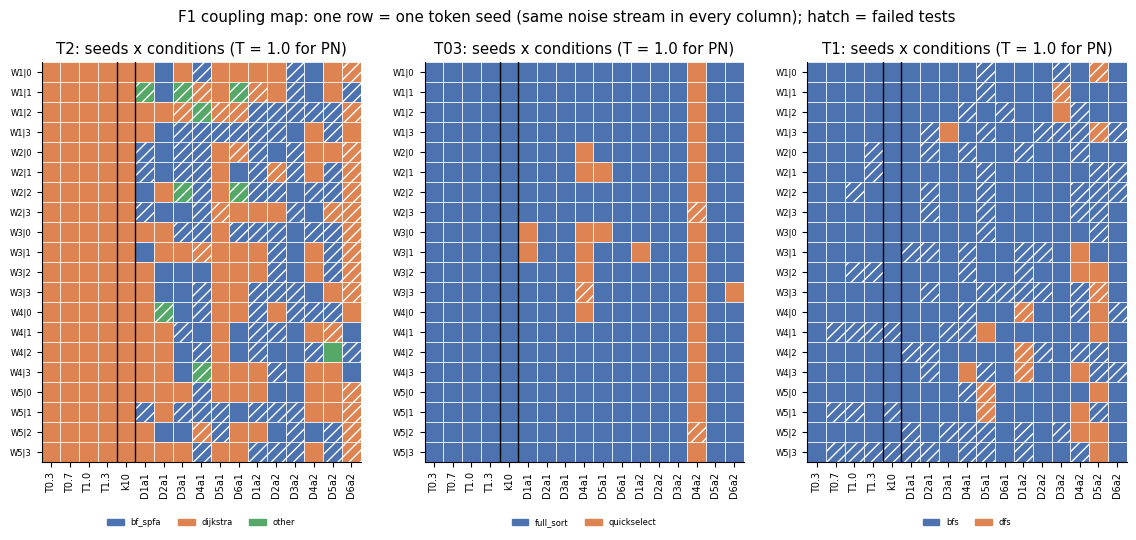

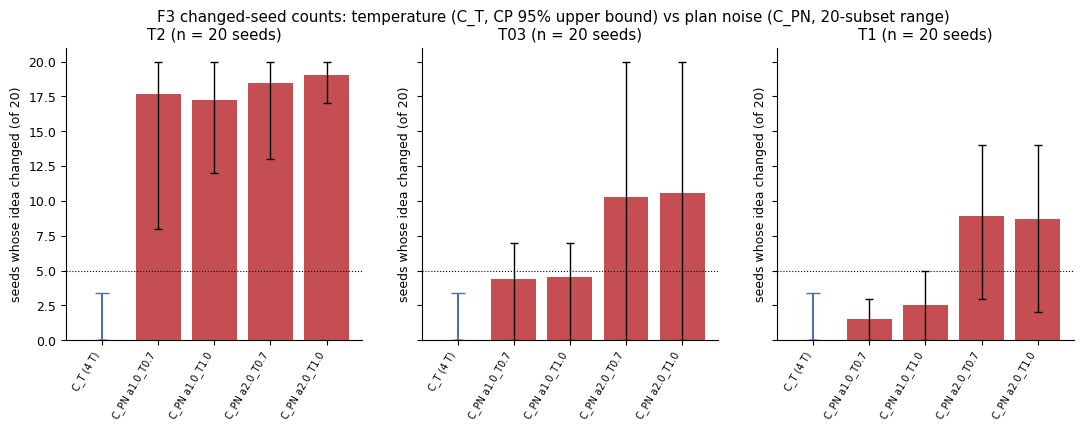

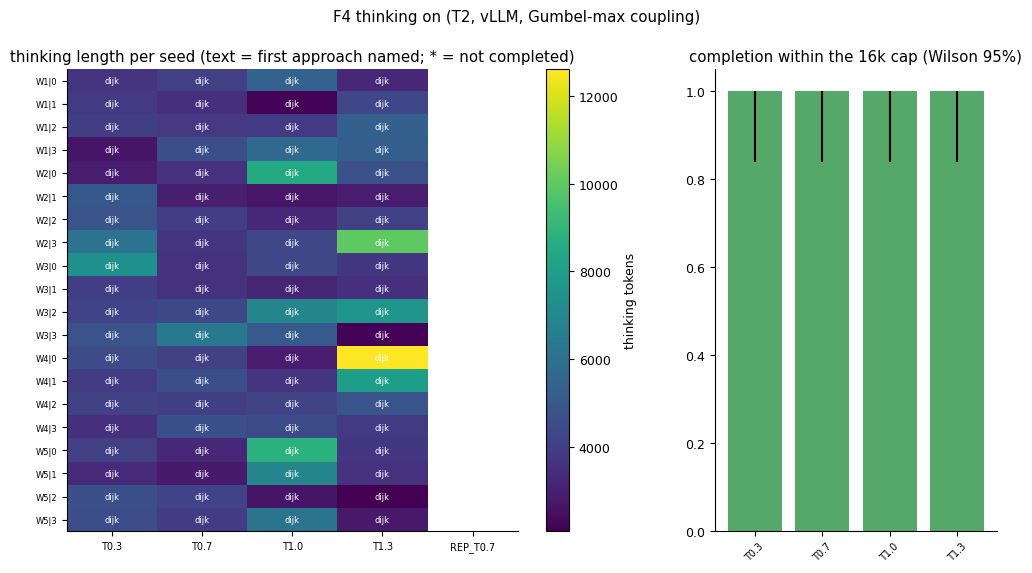

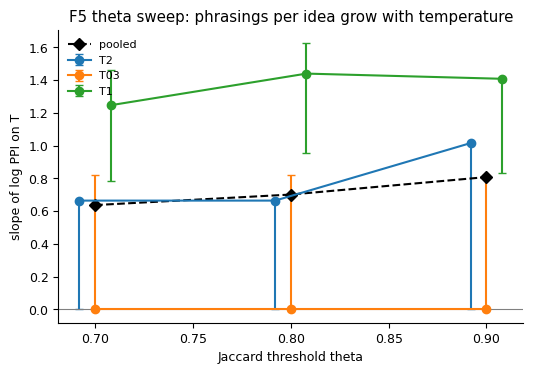

In [22]:
rows = load_rows()
idx = core.index_rows(rows)
f1_coupling(idx)                                                    # per-seed labels: temperature vs plan noise
f3_counts(res)                                                      # C_T vs C_PN per task
f4_thinking(th, [r for r in rows if r["arm"].startswith("THINK")])  # thinking on, T2
f5_theta(phr)                                                       # PPI slope on T across theta